In [1]:
from datasets import load_dataset
from collections import Counter

In [2]:

from datasets import load_dataset
import pandas as pd

dataset = load_dataset("stanfordnlp/sst2")

train = dataset["train"].to_pandas()
heldout = dataset["validation"].to_pandas()

summary = []

for name, df in [("Train", train), ("Held-out", heldout)]:
    df["length"] = df["sentence"].str.split().str.len()

    summary.append({
        "split": name,
        "examples": len(df),
        "positive_%": round(100 * (df["label"] == 1).mean(), 2),
        "mean_length": round(df["length"].mean(), 2),
        "median_length": df["length"].median(),
        "p90_length": df["length"].quantile(0.9),
        "short_<=5_%": round(100 * (df["length"] <= 5).mean(), 2),
        "long_>=20_%": round(100 * (df["length"] >= 20).mean(), 2),
        "unique_sentences": df["sentence"].nunique()
    })

pd.DataFrame(summary)


,split,examples,positive_%,mean_length,median_length,p90_length,short_<=5_%,long_>=20_%,unique_sentences
0,Train,67349,55.78,9.41,7.0,21.0,42.51,12.31,66978
1,Held-out,872,50.92,19.55,19.0,31.9,2.75,47.59,872


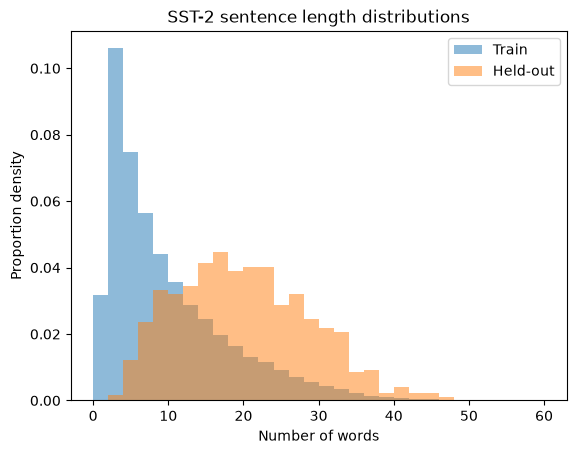

In [ ]:
import matplotlib.pyplot as plt

plt.hist(train["length"], bins=range(0, 62, 2),
         density=True, alpha=0.5, label="Train")

plt.hist(heldout["length"], bins=range(0, 62, 2),
         density=True, alpha=0.5, label="Held-out")

plt.xlabel("Number of words")
plt.ylabel("Proportion density")
plt.title("SST-2 sentence length distributions")
plt.legend()
plt.show()


In [4]:

def normalise(text):
    return " ".join(text.lower().split())

train_texts = train["sentence"].map(normalise)
heldout_texts = heldout["sentence"].map(normalise)

print("Duplicate training rows:", train_texts.duplicated().sum())
print("Duplicate held-out rows:", heldout_texts.duplicated().sum())
print("Held-out texts also in train:",
      heldout_texts.isin(set(train_texts)).sum())


Duplicate training rows: 371
Duplicate held-out rows: 0
Held-out texts also in train: 0


In [5]:

bins = [0, 5, 10, 20, 30, float("inf")]
labels = ["1-5", "6-10", "11-20", "21-30", "31+"]

for name, df in [("Train", train), ("Held-out", heldout)]:
    df["length_group"] = pd.cut(df["length"], bins=bins, labels=labels)

    print(f"\n{name}")
    print(df.groupby("length_group", observed=False).agg(
        examples=("label", "size"),
        positive_rate=("label", "mean")
    ))



Train
              examples  positive_rate
length_group                         
1-5              28631       0.593832
6-10             16130       0.552325
11-20            15216       0.513407
21-30             5660       0.513251
31+               1712       0.549650

Held-out
              examples  positive_rate
length_group                         
1-5                 24       0.375000
6-10               128       0.468750
11-20              340       0.514706
21-30              275       0.541818
31+                105       0.485714
